Dataset loaded successfully!
Dataset shape: (150, 5)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

--- Model Evaluation ---
Model Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93    

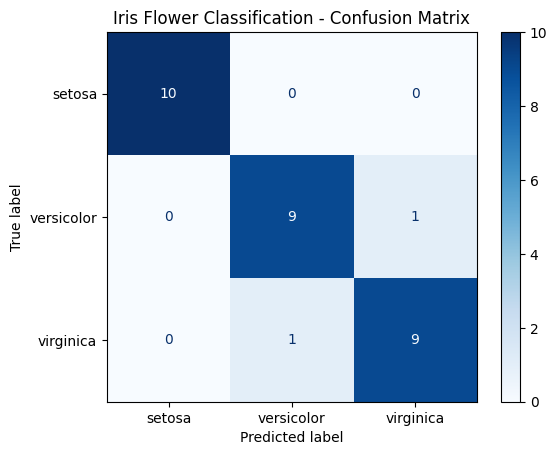

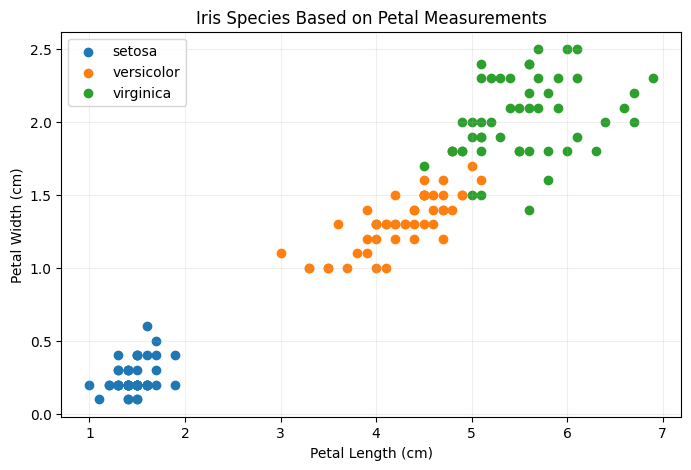

Sample flower prediction: setosa

Task 1 execution completed!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [1]:
# CodeAlpha Data Science Internship
# Task 1: Iris Flower Classification

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load the dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Train the machine learning model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

# 4. Make predictions
y_pred = model.predict(X_test)

# 5. Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print("\n--- Model Evaluation ---")
print(f"Model Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))

# 6. Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()

# 7. Visualize flower measurements
plt.figure(figsize=(8, 5))

for species_id, species_name in enumerate(iris.target_names):
    mask = y == species_id
    plt.scatter(
        X.loc[mask, "petal length (cm)"],
        X.loc[mask, "petal width (cm)"],
        label=species_name
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Species Based on Petal Measurements")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# 8. Try predicting a new flower
sample = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(sample)[0]

print("Sample flower prediction:", iris.target_names[prediction])
print("\nTask 1 execution completed!")